In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [7]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['species'] = iris.target

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  


In [8]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None

Statistical Description:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4

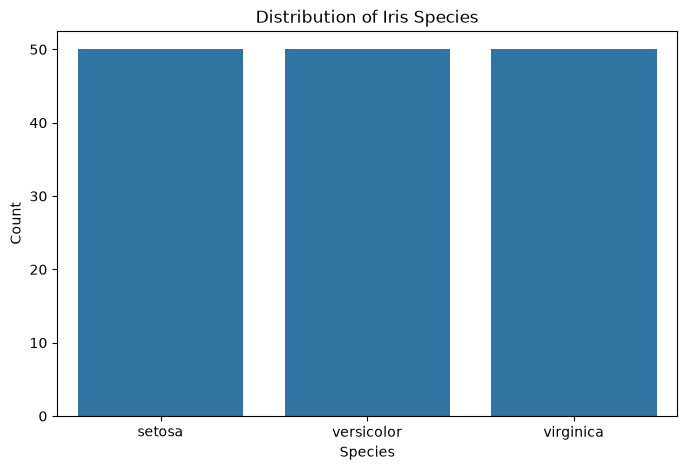

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='species'
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.xticks(
    [0, 1, 2],
    iris.target_names
)

plt.show()

In [10]:
X = df.drop('species', axis=1).values
y = df['species'].values

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (150, 4)
Target Shape: (150,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


### Understanding Gini Impurity
Before implementing CART, we need to understand its most important concept: Gini Impurity.
CART uses Gini Impurity to determine the best feature and threshold for splitting the dataset.

The formula is:
$$Gini = 1 - \sum_{i=1}^{n} p_i^2$$

Where:
- $p_i$ = proportion of samples belonging to class $i$
- $n$ = number of classes

Interpretation:
- $Gini = 0$ means the node is completely pure (all samples belong to a single class).
- Higher Gini means greater mixing of different classes.

In [13]:
def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    classes, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    gini = 1.0 - np.sum(probabilities ** 2)
    return gini

# Test the function
print("Gini Impurity (Training Set):", gini_impurity(y_train))

Gini Impurity (Training Set): 0.6666666666666667


In [14]:
def weighted_gini(left_y, right_y):
    total = len(left_y) + len(right_y)
    if total == 0:
        return 0.0

    left_weight = len(left_y) / total
    right_weight = len(right_y) / total

    return (
        left_weight * gini_impurity(left_y)
        + right_weight * gini_impurity(right_y)
    )

In [15]:
def best_split(X, y):
    best_gini = float('inf')
    best_feature = None
    best_threshold = None

    n_samples, n_features = X.shape

    for feature in range(n_features):
        values = np.unique(X[:, feature])
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            left_mask = X[:, feature] <= threshold
            right_mask = X[:, feature] > threshold

            left_y = y[left_mask]
            right_y = y[right_mask]

            if len(left_y) == 0 or len(right_y) == 0:
                continue

            gini = weighted_gini(left_y, right_y)

            if gini < best_gini:
                best_gini = gini
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_gini

# Test the function
feature, threshold, gini = best_split(X_train, y_train)
print("Best Feature:", iris.feature_names[feature])
print("Best Threshold:", threshold)
print("Weighted Gini:", gini)

Best Feature: petal length (cm)
Best Threshold: 2.45
Weighted Gini: 0.3333333333333333


In [16]:
class Node:
    def __init__(
        self,
        feature=None,
        threshold=None,
        left=None,
        right=None,
        value=None
    ):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

In [17]:
def build_tree(
    X,
    y,
    depth=0,
    max_depth=5,
    min_samples_split=2
):
    # Find majority class
    classes, counts = np.unique(y, return_counts=True)
    majority_class = classes[np.argmax(counts)]

    # Stopping conditions
    if (
        len(classes) == 1
        or depth >= max_depth
        or len(y) < min_samples_split
    ):
        return Node(value=majority_class)

    # Find the best split
    feature, threshold, gini = best_split(X, y)

    # Stop if no valid split reduces impurity
    if feature is None:
        return Node(value=majority_class)

    # Divide dataset
    left_mask = X[:, feature] <= threshold
    right_mask = X[:, feature] > threshold

    left_child = build_tree(
        X[left_mask],
        y[left_mask],
        depth=depth + 1,
        max_depth=max_depth,
        min_samples_split=min_samples_split
    )

    right_child = build_tree(
        X[right_mask],
        y[right_mask],
        depth=depth + 1,
        max_depth=max_depth,
        min_samples_split=min_samples_split
    )

    return Node(
        feature=feature,
        threshold=threshold,
        left=left_child,
        right=right_child
    )

In [18]:
cart_tree = build_tree(
    X_train,
    y_train,
    max_depth=5,
    min_samples_split=2
)

print("CART Model Successfully Trained!")

CART Model Successfully Trained!


In [19]:
def predict_sample(node, sample):
    if node.value is not None:
        return node.value

    if sample[node.feature] <= node.threshold:
        return predict_sample(node.left, sample)
    else:
        return predict_sample(node.right, sample)

In [20]:
def predict_tree(tree, X):
    predictions = []
    for sample in X:
        prediction = predict_sample(tree, sample)
        predictions.append(prediction)
    return np.array(predictions)

y_pred = predict_tree(cart_tree, X_test)

print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [21]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [22]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



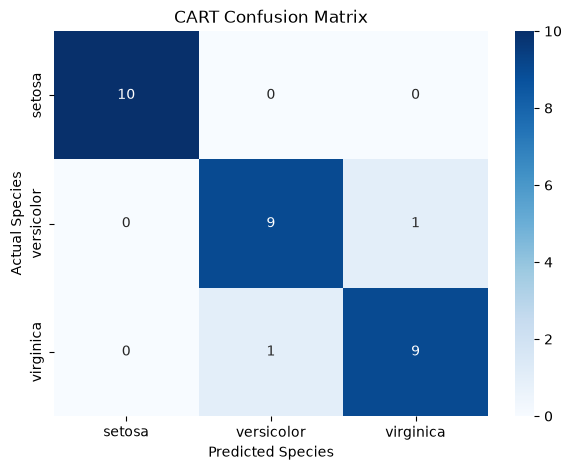

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("CART Confusion Matrix")
plt.show()

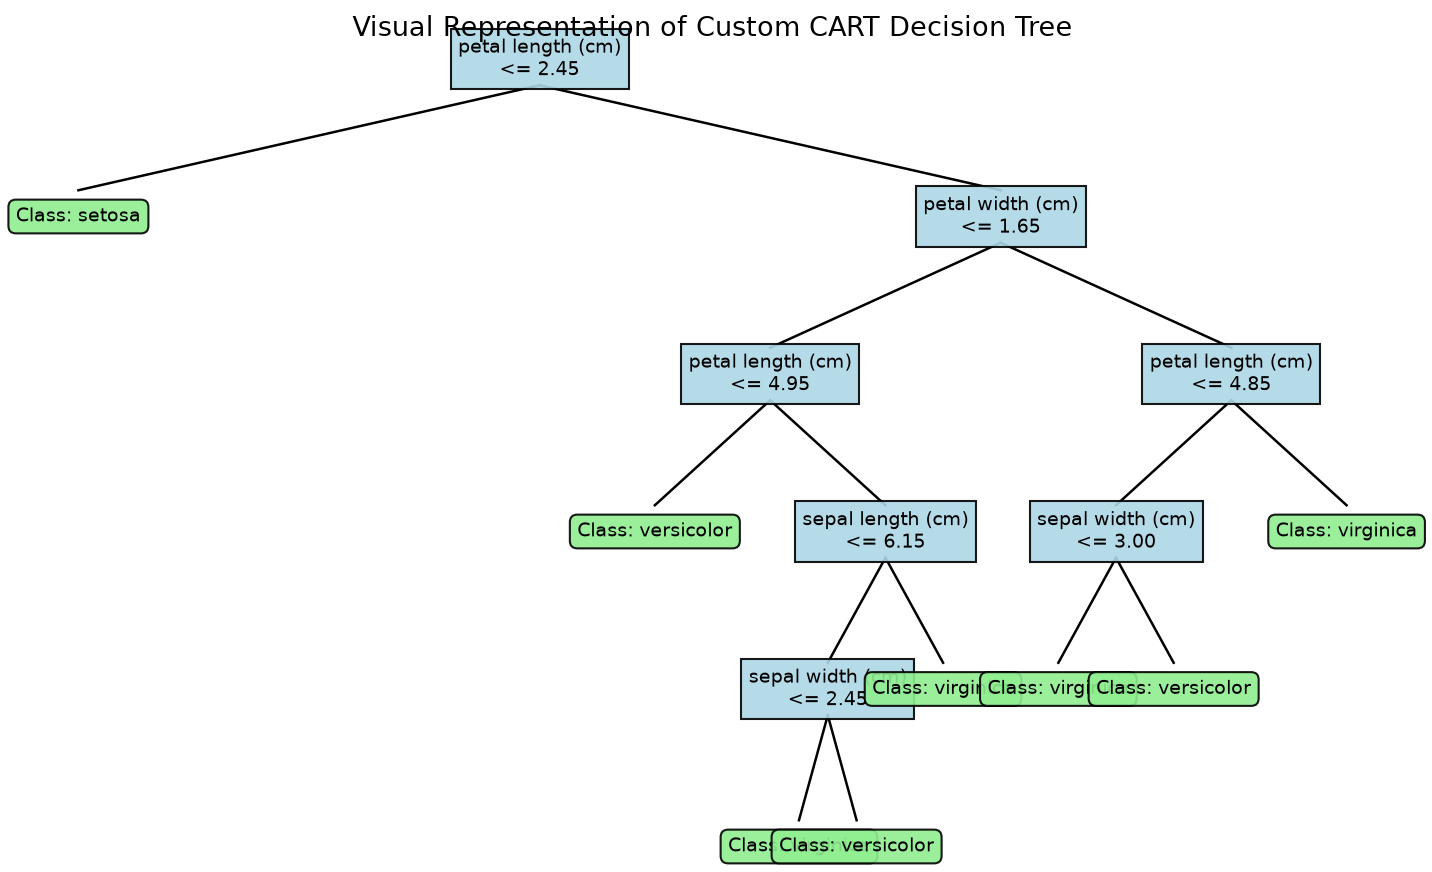

In [24]:
def plot_tree_diagram(node, x=0.5, y=1.0, dx=0.25, dy=0.18):
    if node is None:
        return

    # Leaf node
    if node.value is not None:
        plt.text(
            x, y,
            f"Class: {iris.target_names[node.value]}",
            ha='center', va='center',
            bbox=dict(boxstyle="round,pad=0.4", facecolor='lightgreen', edgecolor='black', alpha=0.9),
            fontsize=9
        )
        return

    # Decision node
    feature_name = iris.feature_names[node.feature]
    label = f"{feature_name}\n<= {node.threshold:.2f}"
    plt.text(
        x, y,
        label,
        ha='center', va='center',
        bbox=dict(boxstyle="square,pad=0.4", facecolor='lightblue', edgecolor='black', alpha=0.9),
        fontsize=9
    )

    # Plot branches
    if node.left:
        plt.plot([x, x - dx], [y - 0.03, y - dy + 0.03], '-k', lw=1.2)
        plot_tree_diagram(node.left, x - dx, y - dy, dx / 2, dy)

    if node.right:
        plt.plot([x, x + dx], [y - 0.03, y - dy + 0.03], '-k', lw=1.2)
        plot_tree_diagram(node.right, x + dx, y - dy, dx / 2, dy)

plt.figure(figsize=(12, 7), dpi=150)
plot_tree_diagram(cart_tree)
plt.axis('off')
plt.title("Visual Representation of Custom CART Decision Tree", fontsize=13)
plt.show()

In [26]:
print("========== CART MODEL RESULTS ==========")
print("Dataset: Iris Flower Dataset")
print("Total Samples:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Algorithm: CART")
print("Splitting Criterion: Gini Impurity")
print("Maximum Tree Depth: 5")
print("========================================")

========== CART MODEL RESULTS ==========
Dataset: Iris Flower Dataset
Total Samples: 150
Training Samples: 120
Testing Samples: 30
Algorithm: CART
Splitting Criterion: Gini Impurity
Maximum Tree Depth: 5


## Conclusion
The CART algorithm was successfully implemented from scratch using Python. The Iris dataset was used to classify flowers into three different species. Gini Impurity was used as the splitting criterion to identify the best feature and threshold. The model was trained using a recursive tree construction method and evaluated using testing data. The performance was measured using accuracy, precision, recall, F1-score, and a confusion matrix. Thus, the implementation demonstrates how the CART algorithm works for classification problems.